# 02d · Análisis: cómo cambió la desigualdad y su relación con la demografía

**Pregunta:** *Entre 2006 y 2025, mientras bajaban la fecundidad y la mortalidad infantil en América Latina, ¿se redujo o creció la desigualdad de aprendizaje dentro de los países?*

Este notebook profundiza tres puntos que dejó abiertos `02c_tendencias_america_latina`:

1. **¿Cómo cambió la brecha?** Con los cambios oficiales de la OCDE entre 2009 y 2025, cuyos errores estándar ya incluyen el error de enlace entre ciclos.
2. **¿Es un efecto de la cobertura?** Cada vez más jóvenes de 15 años entran a PISA; se comprueba si eso explica los cambios en la parte alta de la distribución.
3. **¿Importa la demografía del año de nacimiento?** Se prueba la fecundidad y la mortalidad infantil del año en que nacieron los evaluados (ciclo − 15) en lugar de las del año de la prueba.

### Reglas fijadas antes de ver los resultados (Guía Ética, B3)

**Tipología del cambio de la brecha** (por país y materia, de 2009 a 2025), según cómo se movieron los percentiles 10 (rezagados) y 90 (mejores):

| La brecha... | Condición | Nombre |
|---|---|---|
| se cierra (ΔP90 < ΔP10) | los rezagados suben (ΔP10 > 0) | **Cierre hacia arriba** |
| se cierra (ΔP90 < ΔP10) | los rezagados no suben (ΔP10 ≤ 0): todos bajan, los mejores más | **Cierre hacia abajo** |
| se abre (ΔP90 > ΔP10) | los mejores suben (ΔP90 > 0) | **Apertura hacia arriba** |
| se abre (ΔP90 > ΔP10) | los mejores no suben (ΔP90 ≤ 0): todos bajan, los rezagados más | **Apertura hacia abajo** |

Un cambio se considera **claro** si supera 1,96 veces su error estándar.

**Supuesto para corregir por cobertura:** los jóvenes de 15 años que PISA no cubre (no escolarizados o en grados muy bajos) no estarían entre el 25 % con mejor puntaje de su generación. Es un supuesto débil y verosímil, y permite calcular los percentiles 75 y 90 de **toda la generación**, que son comparables entre ciclos aunque la cobertura cambie.

In [1]:
%load_ext autoreload
%autoreload 2

import re
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

from src.utils import DATA_RAW, cargar_processed, guardar_processed
from src.estilo import aplicar_estilo, PALETA, DESTACADO, GRIS

aplicar_estilo()
pd.set_option("display.max_columns", None)

panel = cargar_processed("al_panel_pisa.csv")
PAISES = sorted(panel["Pais"].unique())
COLOR = dict(zip(PAISES, PALETA))
MATERIAS = ["Matematicas", "Lectura", "Ciencias"]
INICIO, FIN = 2009, 2025
print(panel.shape)

(168, 29)


## 1. ¿Cómo cambió la brecha entre 2009 y 2025?

### Cambios oficiales de la OCDE

Las tablas de tendencia traen columnas *Change in percentiles between 2009 and 2025* y *Change between 2009 and 2025* (para el % bajo el nivel 2). Sus errores estándar incluyen el error de enlace entre las escalas de los dos ciclos (OCDE, *PISA 2025 Results, Vol. I*, anexo A3), así que son la forma correcta de decir si un percentil subió o bajó.

In [2]:
EXCEL = DATA_RAW / "PISA2025_cap2a_desempeno_niveles.xlsx"
HOJAS = {"Matematicas": ("Table I.B1.2a.41", "Table I.B1.2a.35"),
         "Lectura": ("Table I.B1.2a.40", "Table I.B1.2a.34"),
         "Ciencias": ("Table I.B1.2a.39", "Table I.B1.2a.33")}
NOMBRE_A_PAIS = {p: p for p in PAISES}


def limpiar_nombre(nombre):
    return re.sub(r"[\*\d]+$", "", str(nombre)).strip()


def leer_cambio(hoja, medidas):
    # Lee las columnas de cambio 2009 -> 2025 (valor y error estándar) para las medidas pedidas
    t = pd.read_excel(EXCEL, sheet_name=hoja, header=None)
    fila = next(i for i in range(len(t)) if t.iloc[i].astype(str).str.contains(f"between {INICIO} and {FIN}").any())
    encabezado, medida, tipo = t.iloc[fila].ffill(), t.iloc[fila + 1].ffill(), t.iloc[fila + 2]
    nombres = t.iloc[fila + 3:, 0].map(limpiar_nombre)
    salida = pd.DataFrame({"Pais": nombres.values})
    for corto, largo in medidas.items():
        for j in range(t.shape[1]):
            if f"between {INICIO} and {FIN}" in str(encabezado[j]) and str(medida[j]).startswith(largo):
                sufijo = "_se" if str(tipo[j]).strip() == "S.E." else ""
                salida[f"d{corto}{sufijo}"] = pd.to_numeric(t.iloc[fila + 3:, j], errors="coerce").values
    return salida.loc[salida["Pais"].isin(PAISES)].drop_duplicates("Pais").set_index("Pais")


PERC = {"P10": "10th percentile", "P25": "25th percentile", "P50": "Median", "P75": "75th percentile", "P90": "90th percentile"}
partes = []
for materia, (hoja_dist, hoja_bajo) in HOJAS.items():
    c = leer_cambio(hoja_dist, PERC).join(leer_cambio(hoja_bajo, {"Bajo2": "Below Level 2"}))
    partes.append(c.assign(Materia=materia).reset_index())
cambios = pd.concat(partes, ignore_index=True)
print(cambios.shape)

# Validación: los cambios oficiales deben coincidir con la resta de los niveles de 02b
niveles = panel.loc[panel["Time"].isin([INICIO, FIN])].pivot_table(index=["Pais", "Materia"], columns="Time", values=["P10", "P90"])
for p in ["P10", "P90"]:
    resta = (niveles[(p, FIN)] - niveles[(p, INICIO)]).rename("resta").reset_index()
    comp = cambios.merge(resta, on=["Pais", "Materia"])
    print(f"{p}: máx. |cambio oficial - resta de niveles| = {(comp[f'd{p}'] - comp['resta']).abs().max():.3f} puntos")

(24, 14)
P10: máx. |cambio oficial - resta de niveles| = 0.000 puntos
P90: máx. |cambio oficial - resta de niveles| = 0.000 puntos


### Tipología: ¿hacia arriba o hacia abajo?

El cambio de la brecha es ΔP90 − ΔP10. Su error estándar se aproxima con los de las brechas de cada ciclo: el error de enlace afecta igual a los dos percentiles de un mismo ciclo y se cancela en la brecha.

In [3]:
se_brecha = panel.loc[panel["Time"].isin([INICIO, FIN])].pivot_table(index=["Pais", "Materia"], columns="Time", values="brecha_P90_P10_se")
se_brecha = np.sqrt(se_brecha[INICIO] ** 2 + se_brecha[FIN] ** 2).rename("dBrecha_se").reset_index()
cambios = cambios.merge(se_brecha, on=["Pais", "Materia"])
cambios["dBrecha"] = cambios["dP90"] - cambios["dP10"]


def claro(valor, se):
    return np.abs(valor) > 1.96 * se


def tipologia(f):
    if f["dP90"] < f["dP10"]:
        return "Cierre hacia arriba" if f["dP10"] > 0 else "Cierre hacia abajo"
    return "Apertura hacia arriba" if f["dP90"] > 0 else "Apertura hacia abajo"


cambios["tipo"] = cambios.apply(tipologia, axis=1)
for v in ["dBrecha", "dP10", "dP90", "dBajo2"]:
    cambios[f"{v}_claro"] = claro(cambios[v], cambios[f"{v}_se"])

tabla = cambios[["Materia", "Pais", "tipo", "dBrecha", "dBrecha_claro", "dP10", "dP10_claro", "dP90", "dP90_claro", "dBajo2", "dBajo2_claro"]]
tabla = tabla.sort_values(["Materia", "dBrecha"]).round(1)
tabla

,Materia,Pais,tipo,dBrecha,dBrecha_claro,dP10,dP10_claro,dP90,dP90_claro,dBajo2,dBajo2_claro
16,Ciencias,Argentina,Cierre hacia arriba,-24.3,True,9.4,False,-14.9,False,6.9,False
22,Ciencias,Peru,Cierre hacia arriba,-20.8,True,47.2,True,26.4,True,-15.8,True
23,Ciencias,Uruguay,Cierre hacia arriba,-18.4,True,27.3,True,8.8,False,-6.8,True
21,Ciencias,Mexico,Cierre hacia arriba,-5.6,False,1.7,False,-3.9,False,2.2,False
20,Ciencias,Costa Rica,Apertura hacia arriba,14.3,False,-11.5,False,2.8,False,5.4,False
18,Ciencias,Chile,Apertura hacia arriba,18.2,True,-13.4,False,4.9,False,4.4,False
19,Ciencias,Colombia,Apertura hacia arriba,24.7,True,3.3,False,28.0,True,-4.0,False
17,Ciencias,Brazil,Apertura hacia arriba,29.6,True,-11.3,False,18.4,True,-1.7,False
8,Lectura,Argentina,Cierre hacia arriba,-43.6,True,17.9,False,-25.7,True,8.0,True
14,Lectura,Peru,Cierre hacia arriba,-28.2,True,36.6,True,8.5,False,-6.6,True


In [4]:
resumen = pd.crosstab(cambios["tipo"], cambios["Materia"])[MATERIAS]
resumen.loc["Total"] = resumen.sum()
print("Países por tipo de cambio (de 8 en cada materia):")
display(resumen)

claros = cambios.groupby("Materia").agg(
    brecha_cierra_claro=("dBrecha", lambda s: int(((s < 0) & cambios.loc[s.index, "dBrecha_claro"]).sum())),
    brecha_abre_claro=("dBrecha", lambda s: int(((s > 0) & cambios.loc[s.index, "dBrecha_claro"]).sum())),
    P90_baja_claro=("dP90", lambda s: int(((s < 0) & cambios.loc[s.index, "dP90_claro"]).sum())),
    P10_baja_claro=("dP10", lambda s: int(((s < 0) & cambios.loc[s.index, "dP10_claro"]).sum())),
    P10_sube_claro=("dP10", lambda s: int(((s > 0) & cambios.loc[s.index, "dP10_claro"]).sum())),
    bajo2_sube_claro=("dBajo2", lambda s: int(((s > 0) & cambios.loc[s.index, "dBajo2_claro"]).sum())),
).loc[MATERIAS]
print("Cambios claros (|cambio| > 1,96 errores estándar), número de países:")
claros

Países por tipo de cambio (de 8 en cada materia):
Cambios claros (|cambio| > 1,96 errores estándar), número de países:


Materia,Matematicas,Lectura,Ciencias
tipo,,,
Apertura hacia abajo,1,2,0
Apertura hacia arriba,1,2,4
Cierre hacia abajo,5,2,0
Cierre hacia arriba,1,2,4
Total,8,8,8


,brecha_cierra_claro,brecha_abre_claro,P90_baja_claro,P10_baja_claro,P10_sube_claro,bajo2_sube_claro
Materia,,,,,,
Matematicas,4,0,5,4,1,5
Lectura,3,1,3,3,1,5
Ciencias,3,3,0,0,2,0


### El mapa del cambio

Cada punto es un país: en el eje horizontal, cuánto cambió su percentil 10 (los rezagados); en el vertical, cuánto cambió su percentil 90 (los mejores). La diagonal separa los países donde la brecha se cerró (debajo) de aquellos donde se abrió (encima). Las barras son intervalos del 95 % con el error de enlace incluido.

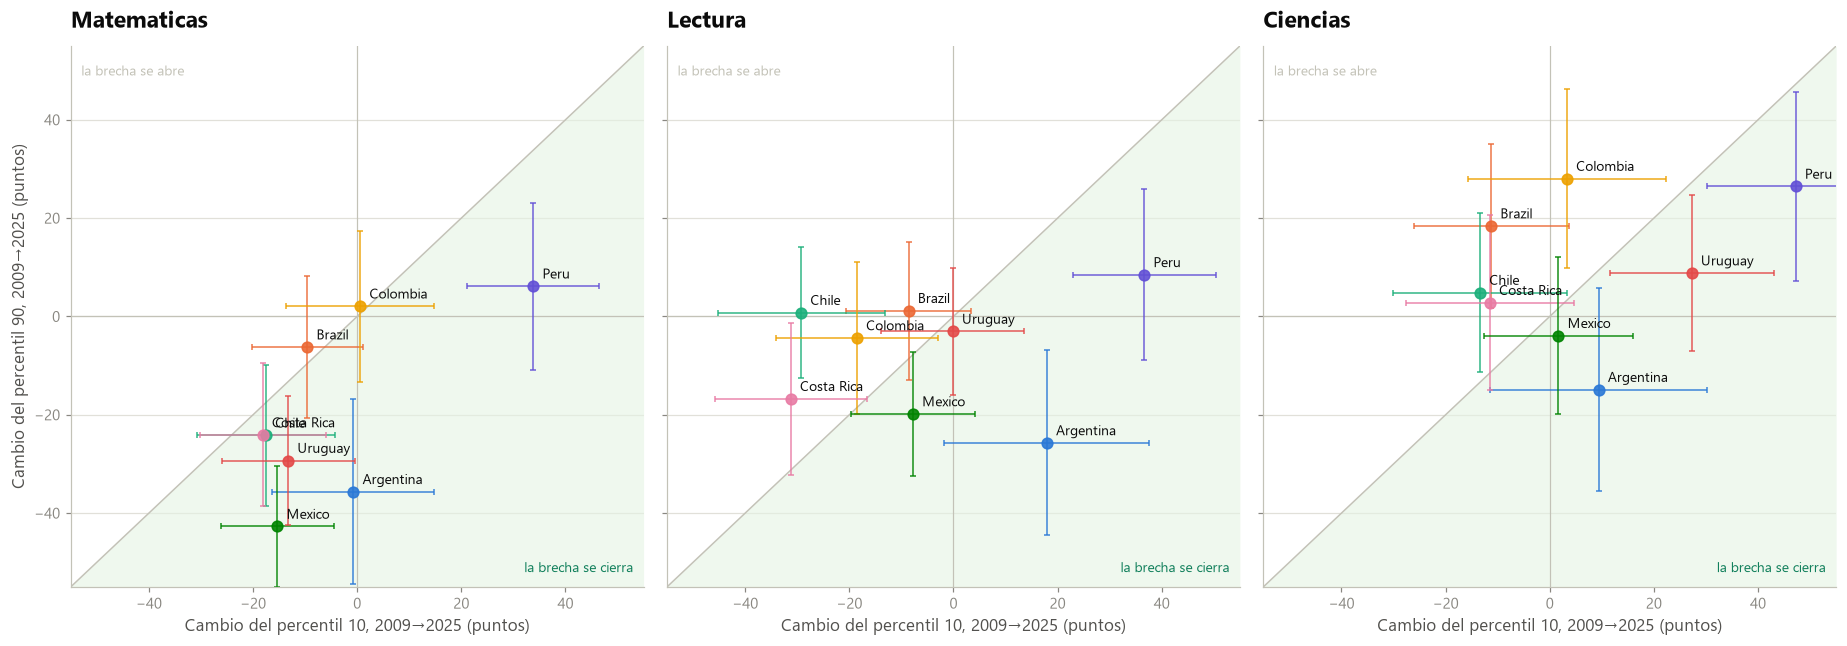

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6), sharex=True, sharey=True)
lim = 55
for ax, materia in zip(axes, MATERIAS):
    d = cambios.loc[cambios["Materia"].eq(materia)]
    ax.fill_between([-lim, lim], [-lim, lim], -lim, color="#e5f4e4", alpha=0.6, lw=0)
    ax.plot([-lim, lim], [-lim, lim], color=GRIS, lw=1)
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.axvline(0, color=GRIS, lw=0.8)
    for _, f in d.iterrows():
        ax.errorbar(f["dP10"], f["dP90"], xerr=1.96 * f["dP10_se"], yerr=1.96 * f["dP90_se"],
                    fmt="o", color=COLOR[f["Pais"]], ms=7, capsize=2, lw=1, alpha=0.9)
        ax.annotate(f["Pais"], (f["dP10"], f["dP90"]), textcoords="offset points", xytext=(6, 5), fontsize=9)
    ax.text(lim - 2, -lim + 3, "la brecha se cierra", ha="right", fontsize=9, color="#12805c")
    ax.text(-lim + 2, lim - 6, "la brecha se abre", ha="left", fontsize=9, color=GRIS)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), title=materia, xlabel="Cambio del percentil 10, 2009→2025 (puntos)")
axes[0].set_ylabel("Cambio del percentil 90, 2009→2025 (puntos)")
plt.tight_layout()

## 2. ¿Es un efecto de la cobertura?

Entre 2009 y 2025 la cobertura de PISA subió entre 9 y 20 puntos porcentuales en los 8 países. Si los que entran ahora a la prueba son jóvenes que antes no llegaban escolarizados a los 15 años, suelen ubicarse abajo en la distribución. Eso empuja **mecánicamente** hacia abajo todos los percentiles observados, aunque nadie haya aprendido menos.

Con el supuesto fijado al inicio (los no cubiertos no estarían en el 25 % superior de su generación), el 10 % superior de **toda la generación** es el $0{,}10 / c$ superior de los evaluados, donde $c$ es la cobertura. Por tanto:

$$P90_{\text{generación}} = \text{percentil } \left(1 - \tfrac{0{,}10}{c}\right) \text{ de los evaluados}, \qquad P75_{\text{generación}} = \text{percentil } \left(1 - \tfrac{0{,}25}{c}\right)$$

Ese percentil se interpola entre los cinco que publica la OCDE (10, 25, 50, 75 y 90), en escala normal porque las distribuciones de PISA son aproximadamente normales. La parte baja de la generación no se puede calcular así: no hay datos de quienes no presentan la prueba.

In [6]:
Z = stats.norm.ppf([0.10, 0.25, 0.50, 0.75, 0.90])


def percentil_evaluados(fila, p):
    puntajes = fila[["P10", "P25", "P50", "P75", "P90"]].to_numpy(float)
    return float(np.interp(stats.norm.ppf(p), Z, puntajes))


def percentil_generacion(fila, q):
    # Percentil (1 - q) de toda la generación de 15 años, bajo el supuesto de que los no cubiertos no están en el q superior
    return percentil_evaluados(fila, 1 - q / fila["cobertura_ci3"])


ext = panel.loc[panel["Time"].isin([INICIO, FIN])].copy()
for q, nombre in [(0.10, "P90"), (0.25, "P75")]:
    ext[f"{nombre}_generacion"] = ext.apply(lambda f: percentil_generacion(f, q), axis=1)
    ext[f"pos_{nombre}"] = 100 * (1 - q / ext["cobertura_ci3"])

ancho = ext.pivot_table(index=["Materia", "Pais"], columns="Time",
                        values=["P90", "P90_generacion", "P75", "P75_generacion", "pos_P90", "cobertura_ci3"])
cob = pd.DataFrame({
    "cobertura_2009": ancho[("cobertura_ci3", INICIO)], "cobertura_2025": ancho[("cobertura_ci3", FIN)],
    "P90_evaluados_es_percentil_de_gen_2009": ancho[("pos_P90", INICIO)],
    "dP90_observado": ancho[("P90", FIN)] - ancho[("P90", INICIO)],
    "dP90_generacion": ancho[("P90_generacion", FIN)] - ancho[("P90_generacion", INICIO)],
    "dP75_observado": ancho[("P75", FIN)] - ancho[("P75", INICIO)],
    "dP75_generacion": ancho[("P75_generacion", FIN)] - ancho[("P75_generacion", INICIO)],
}).round(1)
cob[["cobertura_2009", "cobertura_2025"]] = (100 * ancho[[("cobertura_ci3", INICIO), ("cobertura_ci3", FIN)]]).round(0).to_numpy()
print("Para leer la tercera columna: en 2009, el 10 % superior de toda la generación equivalía a evaluados por encima de ese percentil.")
cob.loc[MATERIAS]

Para leer la tercera columna: en 2009, el 10 % superior de toda la generación equivalía a evaluados por encima de ese percentil.


cobertura_2009  cobertura_2025  P90_evaluados_es_percentil_de_gen_2009  dP90_observado  dP90_generacion  dP75_observado  dP75_generacion
Materia     Pais                                                                                                                                                
Matematicas Argentina             69.0            87.0                                    85.4           -35.6            -21.4           -32.9            -12.3
            Brazil                61.0            76.0                                    83.5            -6.2              7.5            -5.7             10.4
            Chile                 85.0            95.0                                    88.3           -24.2            -18.4           -19.0            -11.6
            Colombia              58.0            75.0                                    82.9             2.1             14.1            -0.8             17.5
            Costa Rica            53.0            73.0                                    81.3           -24.1             -8.8           -24.8             -0.7
            Mexico                61.0            69.0                                    83.5           -42.7            -34.8           -40.1            -26.7
            Peru                  73.0            86.0                                    86.3             6.2             15.6             9.7             23.5
            Uruguay               63.0            76.0                                    84.2           -29.3            -17.4           -26.6             -8.6
Lectura     Argentina             69.0            87.0                                    85.4           -25.7            -10.8           -23.6             -0.5
            Brazil                61.0            76.0                                    83.5             1.2             15.6             0.5             20.1
            Chile                 85.0            95.0                                    88.3             0.8              5.6            -5.2              1.5
            Colombia              58.0            75.0                                    82.9            -4.4              7.5           -10.8              8.8
            Costa Rica            53.0            73.0                                    81.3           -16.7             -3.6           -24.6             -0.7
            Mexico                61.0            69.0                                    83.5           -19.8            -14.3           -22.9            -11.4
            Peru                  73.0            86.0                                    86.3             8.5             18.5            13.2             28.3
            Uruguay               63.0            76.0                                    84.2            -3.1              8.1            -3.8             14.1
Ciencias    Argentina             69.0            87.0                                    85.4           -14.9             -1.2           -17.3              4.1
            Brazil                61.0            76.0                                    83.5            18.4             31.0            14.0             28.8
            Chile                 85.0            95.0                                    88.3             4.9              9.9             0.9              7.9
            Colombia              58.0            75.0                                    82.9            28.0             38.1            17.0             34.6
            Costa Rica            53.0            73.0                                    81.3             2.8             16.7            -2.7             18.9
            Mexico                61.0            69.0                                    83.5            -3.9              2.6            -4.9              5.9
            Peru                  73.0            86.0                                    86.3            26.4             36.3            32.3             45.7

In [7]:
r = cob.reset_index().groupby("Materia").agg(
    dP90_obs_mediana=("dP90_observado", "median"), dP90_gen_mediana=("dP90_generacion", "median"),
    paises_P90_gen_baja=("dP90_generacion", lambda s: int((s < 0).sum())),
    dP75_obs_mediana=("dP75_observado", "median"), dP75_gen_mediana=("dP75_generacion", "median"),
    paises_P75_gen_baja=("dP75_generacion", lambda s: int((s < 0).sum())),
).loc[MATERIAS].round(1)
print("Medianas de los 8 países (puntos) y número de países donde la parte alta de la generación bajó:")
r

Medianas de los 8 países (puntos) y número de países donde la parte alta de la generación bajó:


,dP90_obs_mediana,dP90_gen_mediana,paises_P90_gen_baja,dP75_obs_mediana,dP75_gen_mediana,paises_P75_gen_baja
Materia,,,,,,
Matematicas,-24.2,-13.1,5,-21.9,-4.6,5
Lectura,-3.8,6.6,3,-8.0,5.2,3
Ciencias,6.8,19.0,1,6.6,23.8,0


## 3. ¿Importa la demografía del año de nacimiento?

Los evaluados de un ciclo tienen unos 15 años, así que la fecundidad y la mortalidad infantil **de 15 años antes** describen el contexto en el que nació esa misma generación: cuántos hermanos tendían a tener y en qué condiciones de salud nacieron. Se compara con la demografía del año de la prueba.

| Ciclo PISA | Año de nacimiento de los evaluados |
|---|---|
| 2009 | 1994 |
| 2025 | 2010 |

In [8]:
base = panel.loc[panel["Time"].between(INICIO, FIN)]
ini = base.loc[base["Time"].eq(INICIO) & base["Materia"].eq("Matematicas")].set_index("Pais")
fin = base.loc[base["Time"].eq(FIN) & base["Materia"].eq("Matematicas")].set_index("Pais")
variacion = pd.DataFrame({
    "TFR_prueba_2009": ini["TFR"], "TFR_prueba_2025": fin["TFR"],
    "TFR_nacer_1994": ini["TFR_al_nacer"], "TFR_nacer_2010": fin["TFR_al_nacer"],
    "IMR_prueba_2009": ini["IMR"], "IMR_prueba_2025": fin["IMR"],
    "IMR_nacer_1994": ini["IMR_al_nacer"], "IMR_nacer_2010": fin["IMR_al_nacer"],
})
variacion.loc["Mediana"] = variacion.median()
variacion.round(2)

,TFR_prueba_2009,TFR_prueba_2025,TFR_nacer_1994,TFR_nacer_2010,IMR_prueba_2009,IMR_prueba_2025,IMR_nacer_1994,IMR_nacer_2010
Pais,,,,,,,,
Argentina,2.40,1.50,2.94,2.41,13.66,8.70,22.92,13.23
Brazil,1.80,1.60,2.60,1.79,17.24,11.57,43.06,16.47
Chile,1.86,1.13,2.38,1.84,8.09,5.35,12.89,7.87
Colombia,2.10,1.62,2.94,2.01,15.55,9.28,25.13,15.14
Costa Rica,1.95,1.31,2.86,1.83,9.11,6.23,13.01,8.91
Mexico,2.36,1.87,3.13,2.34,16.43,10.02,30.37,15.90
Peru,2.48,1.94,3.43,2.42,16.87,9.81,45.68,16.16
Uruguay,2.02,1.39,2.42,2.01,8.69,5.77,19.41,8.35
Mediana,2.06,1.55,2.90,2.01,14.60,8.99,24.02,14.19


### Entre países: ¿los que más cambiaron su demografía cambiaron más su brecha?

Correlación de Spearman entre el cambio de la brecha (2009→2025) y el cambio de cada indicador demográfico, por materia. n = 8 en cada correlación.

In [9]:
demo_cambio = pd.DataFrame({
    "TFR (año de la prueba)": fin["TFR"] - ini["TFR"],
    "TFR (año de nacimiento)": fin["TFR_al_nacer"] - ini["TFR_al_nacer"],
    "IMR (año de la prueba)": fin["IMR"] - ini["IMR"],
    "IMR (año de nacimiento)": fin["IMR_al_nacer"] - ini["IMR_al_nacer"],
})
filas = []
for materia in MATERIAS:
    db = cambios.loc[cambios["Materia"].eq(materia)].set_index("Pais")["dBrecha"]
    for indicador in demo_cambio:
        rho, p = stats.spearmanr(demo_cambio[indicador], db.loc[demo_cambio.index])
        filas.append({"Materia": materia, "indicador": indicador, "rho": rho, "p": p})
spearman = pd.DataFrame(filas).pivot(index="indicador", columns="Materia", values=["rho", "p"]).round(2)
spearman

rho                            p                    
Materia                 Ciencias Lectura Matematicas Ciencias Lectura Matematicas
indicador                                                                        
IMR (año de la prueba)      0.17    0.62        0.24     0.69    0.10        0.57
IMR (año de nacimiento)     0.07    0.55        0.12     0.87    0.16        0.78
TFR (año de la prueba)      0.60    0.05        0.57     0.12    0.91        0.14
TFR (año de nacimiento)    -0.31   -0.26       -0.36     0.46    0.53        0.39

### Dentro de cada país: modelos de efectos fijos

Para cada materia e indicador: brecha ~ indicador + país, y la misma especificación agregando la cobertura. Usa los 6 ciclos de cada país (47 observaciones; falta Argentina 2015). Errores estándar agrupados por país: con 8 grupos son poco confiables y se leen como orientación.

**Comparaciones múltiples:** aquí se estiman 24 modelos (3 materias × 4 indicadores × 2 especificaciones) y arriba 12 correlaciones. Con tantas pruebas, es esperable que 1 o 2 den p < 0,05 solo por azar. Un resultado cuenta como patrón si se repite entre materias y especificaciones, no por un valor p aislado.

In [10]:
datos = base.dropna(subset=["brecha_P90_P10"]).assign(cobertura_pp=lambda d: 100 * d["cobertura_ci3"])
filas = []
for materia in MATERIAS:
    d = datos.loc[datos["Materia"].eq(materia)]
    for x in ["TFR", "TFR_al_nacer", "IMR", "IMR_al_nacer"]:
        for control, f in [("sin cobertura", f"brecha_P90_P10 ~ {x} + C(Pais)"),
                           ("con cobertura", f"brecha_P90_P10 ~ {x} + cobertura_pp + C(Pais)")]:
            m = smf.ols(f, data=d).fit(cov_type="cluster", cov_kwds={"groups": d["Pais"]})
            filas.append({"Materia": materia, "indicador": x, "control": control,
                          "coef": m.params[x], "ee": m.bse[x], "p": m.pvalues[x], "n": int(m.nobs)})
fe = pd.DataFrame(filas)
print("Coeficiente = puntos de brecha por cada hijo adicional por mujer (TFR) o por cada muerte infantil adicional por 1.000 (IMR)")
fe.pivot_table(index=["indicador", "control"], columns="Materia", values="coef")[MATERIAS].round(1)

Coeficiente = puntos de brecha por cada hijo adicional por mujer (TFR) o por cada muerte infantil adicional por 1.000 (IMR)


Materia                     Matematicas  Lectura  Ciencias
indicador    control                                      
IMR          con cobertura          1.1     -0.2      -1.2
             sin cobertura          2.5     -0.8      -1.7
IMR_al_nacer con cobertura          0.2      0.1      -0.3
             sin cobertura          0.7     -0.1      -0.5
TFR          con cobertura         15.1     -0.1      -1.2
             sin cobertura         22.7     -5.7      -9.1
TFR_al_nacer con cobertura          0.5    -11.6     -13.5
             sin cobertura         13.8     -9.9     -13.2

In [11]:
print("Valores p (agrupados por país):")
display(fe.pivot_table(index=["indicador", "control"], columns="Materia", values="p")[MATERIAS].round(3))
print("Modelos con p < 0,05:", int((fe["p"] < 0.05).sum()), "de", len(fe))

Valores p (agrupados por país):
Modelos con p < 0,05: 5 de 24


Materia                     Matematicas  Lectura  Ciencias
indicador    control                                      
IMR          con cobertura        0.434    0.937     0.595
             sin cobertura        0.010    0.662     0.307
IMR_al_nacer con cobertura        0.561    0.869     0.705
             sin cobertura        0.040    0.835     0.398
TFR          con cobertura        0.004    0.997     0.921
             sin cobertura        0.000    0.722     0.424
TFR_al_nacer con cobertura        0.958    0.420     0.402
             sin cobertura        0.036    0.379     0.191

## 4. Robustez: quitar un país a la vez

Con solo 8 países, un país podría estar cambiando por sí solo las conclusiones. Se repite cada resultado 9 veces: con los 8 países y sacando cada vez a uno. Una conclusión es **robusta** si se mantiene en las 9 versiones.

Conclusiones que se ponen a prueba:

- **A.** En matemáticas, la brecha se cerró desde arriba: la mediana del cambio del percentil 90 es menor (más negativa) que la del percentil 10.
- **B.** En ciencias, ningún país cerró la brecha hacia abajo y, en la mediana, los mejores mejoraron.
- **C.** El cambio de la fecundidad no se relaciona de forma consistente con el cambio de la brecha.

In [12]:
filas = []
for fuera in ["(ninguno)"] + PAISES:
    c = cambios if fuera == "(ninguno)" else cambios.loc[cambios["Pais"].ne(fuera)]
    for materia in MATERIAS:
        d = c.loc[c["Materia"].eq(materia)]
        filas.append({
            "sin": fuera, "Materia": materia, "n": len(d),
            "mediana_dP10": d["dP10"].median(), "mediana_dP90": d["dP90"].median(),
            "cierre_hacia_abajo": int(d["tipo"].eq("Cierre hacia abajo").sum()),
            "cierre_hacia_arriba": int(d["tipo"].eq("Cierre hacia arriba").sum()),
        })
loo = pd.DataFrame(filas)
loo["arriba_menos_abajo"] = loo["mediana_dP90"] - loo["mediana_dP10"]

resumen_loo = loo.groupby("Materia").agg(
    dP90_menos_dP10_min=("arriba_menos_abajo", "min"), dP90_menos_dP10_max=("arriba_menos_abajo", "max"),
    mediana_dP90_min=("mediana_dP90", "min"), mediana_dP90_max=("mediana_dP90", "max"),
    cierre_hacia_abajo_max=("cierre_hacia_abajo", "max"),
).loc[MATERIAS].round(1)
print("Rango en las 9 versiones (con todos y sin cada país):")
resumen_loo

Rango en las 9 versiones (con todos y sin cada país):


,dP90_menos_dP10_min,dP90_menos_dP10_max,mediana_dP90_min,mediana_dP90_max,cierre_hacia_abajo_max
Materia,,,,,
Matematicas,-14.6,-10.9,-24.2,-24.1,5
Lectura,3.4,5.6,-4.4,-3.1,2
Ciencias,1.6,7.1,4.9,8.8,0


In [13]:
mat = loo.loc[loo["Materia"].eq("Matematicas")]
cie = loo.loc[loo["Materia"].eq("Ciencias")]
print("A. Matemáticas: el P90 cae más que el P10 en las 9 versiones:", bool((mat["arriba_menos_abajo"] < 0).all()))
print("B. Ciencias: ningún cierre hacia abajo en las 9 versiones:", bool((cie["cierre_hacia_abajo"] == 0).all()),
      "| mediana del P90 sube en las 9:", bool((cie["mediana_dP90"] > 0).all()))

A. Matemáticas: el P90 cae más que el P10 en las 9 versiones: True
B. Ciencias: ningún cierre hacia abajo en las 9 versiones: True | mediana del P90 sube en las 9: True


In [14]:
# C. Correlación entre países (Spearman) y modelo dentro de cada país, sin cada país
filas = []
for fuera in ["(ninguno)"] + PAISES:
    paises_ok = [x for x in PAISES if x != fuera]
    for materia in MATERIAS:
        db = cambios.loc[cambios["Materia"].eq(materia)].set_index("Pais").loc[paises_ok, "dBrecha"]
        rho, p_rho = stats.spearmanr(demo_cambio.loc[paises_ok, "TFR (año de la prueba)"], db)
        d = datos.loc[datos["Materia"].eq(materia) & datos["Pais"].isin(paises_ok)]
        m = smf.ols("brecha_P90_P10 ~ TFR + cobertura_pp + C(Pais)", data=d).fit(cov_type="cluster", cov_kwds={"groups": d["Pais"]})
        filas.append({"sin": fuera, "Materia": materia, "rho": rho, "p_rho": p_rho, "coef_TFR": m.params["TFR"], "p_coef": m.pvalues["TFR"]})
loo_demo = pd.DataFrame(filas)
rango = loo_demo.groupby("Materia").agg(
    rho_min=("rho", "min"), rho_max=("rho", "max"), p_rho_min=("p_rho", "min"),
    coef_TFR_min=("coef_TFR", "min"), coef_TFR_max=("coef_TFR", "max"),
    versiones_con_p_coef_menor_005=("p_coef", lambda s: int((s < 0.05).sum())),
).loc[MATERIAS].round(2)
print("C. Rango en las 9 versiones. Coeficiente: puntos de brecha por cada hijo por mujer (modelo con cobertura).")
rango

C. Rango en las 9 versiones. Coeficiente: puntos de brecha por cada hijo por mujer (modelo con cobertura).


,rho_min,rho_max,p_rho_min,coef_TFR_min,coef_TFR_max,versiones_con_p_coef_menor_005
Materia,,,,,,
Matematicas,0.36,0.71,0.07,11.98,17.70,8
Lectura,-0.43,0.32,0.34,-15.93,15.89,0
Ciencias,0.39,0.75,0.05,-7.31,10.12,0


## 5. Lo que viene: proyecciones de la ONU a 2050

Para cerrar la historia: qué proyecta la ONU para la fecundidad y la mortalidad infantil de estos países en 2050, con su intervalo de predicción del 95 %. Son **proyecciones**, no datos observados.

In [15]:
al = cargar_processed("al_wpp_1950_2100.csv")
sel = al.loc[al["Time"].isin([2023, 2050]) & (al["en_panel_pisa"] | al["ISO3_code"].eq("AL_REGION"))]
proy = sel.pivot_table(index="Location", columns="Time", values=["TFR", "IMR"])
pi = al.loc[al["Time"].eq(2050)].set_index("Location")
tabla_proy = pd.DataFrame({
    "TFR_2023": proy[("TFR", 2023)], "TFR_2050": proy[("TFR", 2050)],
    "TFR_2050_IP95": pi["TFR_PI95_inf"].round(2).astype(str) + "–" + pi["TFR_PI95_sup"].round(2).astype(str),
    "IMR_2023": proy[("IMR", 2023)], "IMR_2050": proy[("IMR", 2050)],
    "IMR_2050_IP95": pi["IMR_PI95_inf"].round(1).astype(str) + "–" + pi["IMR_PI95_sup"].round(1).astype(str),
}).dropna(subset=["TFR_2023"]).round(2)
tabla_proy

,TFR_2023,TFR_2050,TFR_2050_IP95,IMR_2023,IMR_2050,IMR_2050_IP95
Location,,,,,,
Argentina,1.50,1.54,1.04–2.04,8.98,5.01,2.2–14.0
Brazil,1.62,1.56,0.99–2.1,12.05,6.09,2.8–16.3
Chile,1.17,1.24,0.66–1.76,4.14,2.94,1.5–6.1
Colombia,1.65,1.58,0.95–2.14,9.84,4.56,2.1–11.9
Costa Rica,1.33,1.38,0.82–1.9,6.49,3.24,1.5–6.4
Latin America and the Caribbean,1.81,1.68,1.45–1.91,13.12,6.90,5.1–10.0
Mexico,1.91,1.70,1.08–2.33,10.35,5.18,2.4–13.9
Peru,1.98,1.74,1.08–2.39,11.69,5.25,2.5–12.0
Uruguay,1.41,1.44,0.81–1.97,5.60,3.51,1.8–8.8


In [16]:
region = al.loc[al["ISO3_code"].eq("AL_REGION")].set_index("Time")
print(f"Región, fecundidad en 2050: {region.loc[2050, 'TFR']:.2f} hijos por mujer "
      f"(IP 95 %: {region.loc[2050, 'TFR_PI95_inf']:.2f}–{region.loc[2050, 'TFR_PI95_sup']:.2f}); nivel de reemplazo: 2,1")
print(f"Región, mortalidad infantil en 2050: {region.loc[2050, 'IMR']:.1f} por 1.000 "
      f"(IP 95 %: {region.loc[2050, 'IMR_PI95_inf']:.1f}–{region.loc[2050, 'IMR_PI95_sup']:.1f}); en 2023: {region.loc[2023, 'IMR']:.1f}")
print(f"Año en que la fecundidad de la región bajó de 2,1: {int(region.loc[region['TFR'] < 2.1].index.min())}")

Región, fecundidad en 2050: 1.68 hijos por mujer (IP 95 %: 1.45–1.91); nivel de reemplazo: 2,1
Región, mortalidad infantil en 2050: 6.9 por 1.000 (IP 95 %: 5.1–10.0); en 2023: 13.1
Año en que la fecundidad de la región bajó de 2,1: 2014


### Tabla para las figuras finales

Se guarda una tabla con los cambios 2009→2025 por país y materia (oficiales de la OCDE), la tipología, la corrección por cobertura y los cambios demográficos, para que `03_visualizaciones` no repita cálculos.

In [17]:
salida = (
    cambios.merge(cob.reset_index()[["Materia", "Pais", "dP90_observado", "dP90_generacion", "dP75_generacion"]], on=["Materia", "Pais"])
    .merge(demo_cambio.set_axis(["dTFR", "dTFR_al_nacer", "dIMR", "dIMR_al_nacer"], axis=1).rename_axis("Pais").reset_index(), on="Pais")
)
assert len(salida) == 24
_ = guardar_processed(salida, "al_cambios_2009_2025.csv")

Guardado: data\processed\al_cambios_2009_2025.csv (24 filas)


## 6. Conclusiones

1. **En matemáticas, la brecha se cerró sobre todo «hacia abajo».** Se cerró en 6 de 8 países, y en 5 de ellos (Argentina, México, Uruguay, Chile y Costa Rica) porque los mejores retrocedieron más que los rezagados. El percentil 90 cayó con claridad en 5 países y el % bajo el nivel 2 subió con claridad en 5. Colombia y Brasil casi no cambiaron.
2. **Ese patrón no se repite en las otras materias.** En lectura hay de todo (2 países de cada tipo). En ciencias, la brecha se cerró hacia arriba en 4 países (Argentina, Perú, Uruguay y México) y se abrió hacia arriba en otros 4 (Brasil, Chile, Colombia y Costa Rica): ningún país la cerró hacia abajo, ningún percentil 90 cayó con claridad y el % bajo el nivel 2 no subió con claridad en ninguno.
3. **Perú es el único país que cerró la brecha hacia arriba en las tres materias:** sus rezagados mejoraron entre 34 y 47 puntos.
4. **La cobertura explica parte de la caída de matemáticas, pero no toda.** Al corregir por los jóvenes que antes no llegaban a la prueba, la mediana del cambio del percentil 90 pasa de −24 a −13 puntos. Aun así, el 10 % superior de toda la generación retrocedió en 5 países (México −35, Argentina −21, Chile −18, Uruguay −17 y Costa Rica −9). En lectura y ciencias, una vez corregida la cobertura, la parte alta de la generación mejoró en la mayoría de los países.
5. **La demografía del año de nacimiento no aporta una relación más clara.** La fecundidad al nacer bajó más que la del año de la prueba (mediana de 2,90 a 2,01 hijos frente a 2,06 a 1,55), pero sus correlaciones con el cambio de la brecha son débiles y no significativas (ρ entre −0,26 y −0,36). En los modelos dentro de cada país, solo aparece algo en matemáticas sin controlar la cobertura, y desaparece al controlarla. De 24 modelos, 5 dan p < 0,05, todos en matemáticas y ninguno se repite en lectura o ciencias, cuando por azar se esperaría alrededor de 1.
6. **Las conclusiones resisten quitar cualquier país.** En las 9 versiones (con todos y sin cada uno), el percentil 90 de matemáticas cae más que el 10, y en ciencias ningún país cierra la brecha hacia abajo. La relación con la fecundidad dentro de cada país es robusta **solo en matemáticas** (significativa en 8 de 9 versiones, unos 12 a 18 puntos de brecha por hijo); en lectura y ciencias su signo cambia según qué país se quite.
7. **Lo que viene:** la ONU proyecta para la región 1,68 hijos por mujer en 2050 (IP 95 %: 1,45–1,91), por debajo del reemplazo desde 2014, y una mortalidad infantil de 6,9 por 1.000 (13,1 en 2023). La transición demográfica sigue; la pregunta es si la educación la acompañará.
8. **Respuesta a la pregunta:** mientras la fecundidad y la mortalidad infantil bajaron en los 8 países, la desigualdad de aprendizaje **no siguió un patrón común**: depende de la materia y del país, y no se relaciona de forma consistente con el cambio demográfico.

**Implicación ética (Guía Ética A4 y B3):** la historia de «la brecha se cerró hacia abajo» solo se sostiene en matemáticas. Presentar solo matemáticas sería seleccionar los resultados que convienen; el video debe mostrar las tres materias o explicar por qué se enfoca en una.